In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

In [ ]:
final_output_dir = "../nesy_gnn/results/updated/AD_KG/ANMerge/4/GAT"
result_path = "../nesy_gnn/results/updated/AD_KG/ANMerge/4/GAT/results.pkl"
with open(result_path, 'rb') as f:
    results = pickle.load(f)

In [5]:
def parse_cv_metrics(root_dir):
    dfs = []

    for dirpath, _, filenames in os.walk(root_dir):

        if "cv_all_folds_metrics.tsv" not in filenames:
            continue

        filepath = os.path.join(dirpath, "cv_all_folds_metrics.tsv")

        # path relative to root
        rel = os.path.relpath(dirpath, root_dir)
        parts = rel.split(os.sep)

        # Adjust this according to your folder structure
        if len(parts) < 3:
            continue

        dataset = parts[0]
        k = parts[1]
        model_type = parts[2]

        df = pd.read_csv(filepath, sep="\t")

        # add metadata
        df["dataset"] = dataset
        df["k"] = k
        #df["model_type"] = model_type

        dfs.append(df)

    # merge everything
    all_metrics = pd.concat(dfs, ignore_index=True)

    return all_metrics

In [6]:
def backbone(model):
    if "GCN" in model:
        return "GCN"
    elif "GAT" in model:
        return "GAT"
    elif "GIN" in model:
        return "GIN"
    else:
        return "Other"
        
def boxplot_comparison(df, metric_name, dataset):
    plot_df = df[
        (df["metric"] == metric_name) &
        (df["k"] == '4')
    ]
    plot_df["backbone"] = plot_df["model"].apply(backbone)

    plt.figure(figsize=(12,6))

    fig, ax = plt.subplots(figsize=(10, 6))

    sns.boxplot(
        data=plot_df,
        x="model",
        y="score",
        hue="backbone",
        ax=ax
    )

    sns.move_legend(
        ax,
        "upper left",
        bbox_to_anchor=(1.05, 1),
        title="Metric"
    )

    plt.xticks(rotation=45, ha="right")
    plt.title(f"Performance comparison: {metric_name} | {dataset}")
    plt.tight_layout()
    plt.show()

/tmp/ipykernel_506564/3652178690.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  plot_df["backbone"] = plot_df["model"].apply(backbone)


<Figure size 1200x600 with 0 Axes>

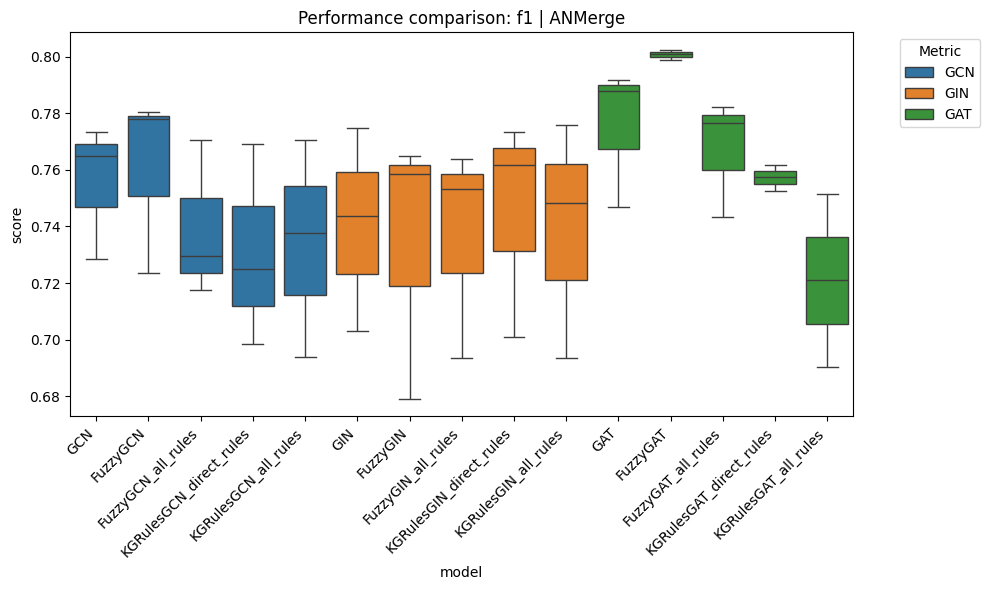

/tmp/ipykernel_506564/3652178690.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  plot_df["backbone"] = plot_df["model"].apply(backbone)


<Figure size 1200x600 with 0 Axes>

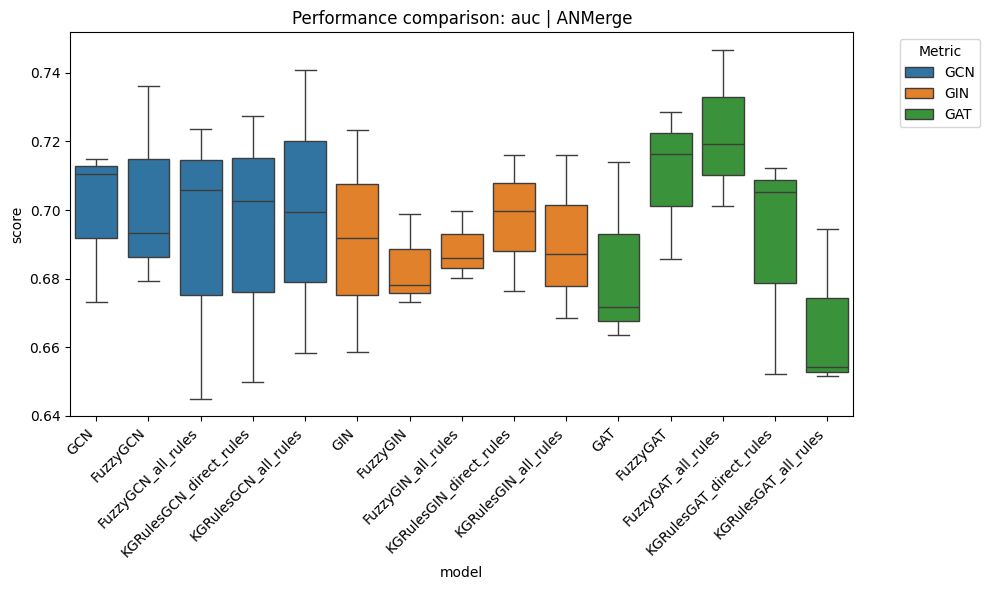

/tmp/ipykernel_506564/3652178690.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  plot_df["backbone"] = plot_df["model"].apply(backbone)


<Figure size 1200x600 with 0 Axes>

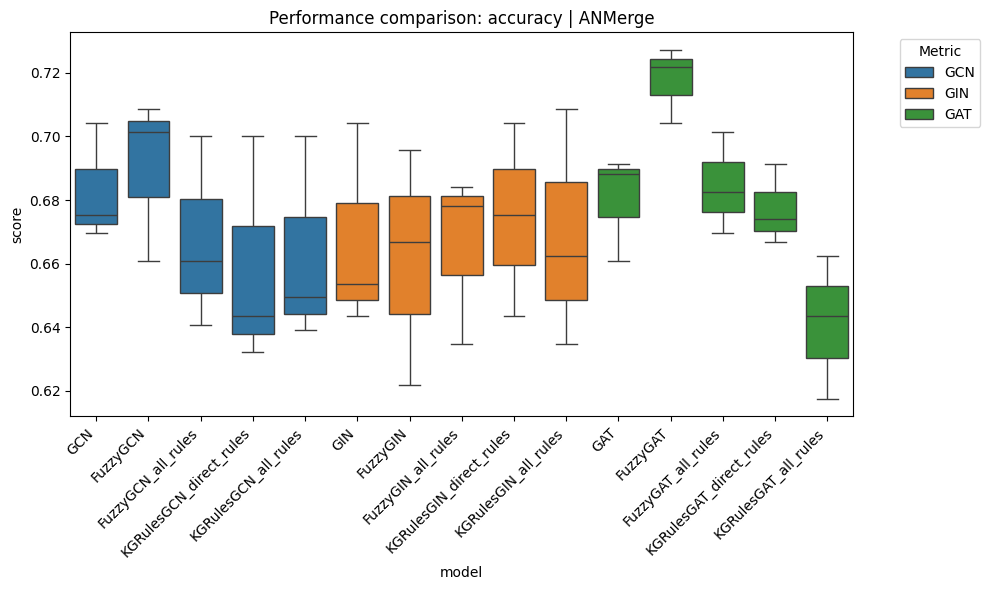

In [47]:
root_dir = "../nesy_gnn/results/AD_KG"
df_metrics = parse_cv_metrics(root_dir)
df = df_metrics.melt(
    id_vars=[
        "dataset",
        "k",
        "model",
        "fold"
    ],
    value_vars=["accuracy", "f1", "auc"],
    var_name="metric",
    value_name="score",
)
metric_name = 'f1'
dataset = 'ANMerge'
boxplot_comparison(df, 'f1', dataset)
boxplot_comparison(df, 'auc', dataset)
boxplot_comparison(df, 'accuracy', dataset)

In [9]:
root_dir = "../nesy_gnn/results/updated/AD_KG"
df_metrics = parse_cv_metrics(root_dir)
df = df_metrics.melt(
    id_vars=[
        "dataset",
        "k",
        "model",
        "fold"
    ],
    value_vars=['accuracy', 'balanced_accuracy', 'f1', 'f1_macro',
       'f1_weighted', 'auroc', 'auprc'],
    var_name="metric",
    value_name="score",
)
df

,dataset,k,model,fold,metric,score
0,ANMerge,4,GAT,0,accuracy,0.696970
1,ANMerge,4,GAT,1,accuracy,0.665217
2,ANMerge,4,GAT,2,accuracy,0.656522
3,ANMerge,4,FuzzyGAT,0,accuracy,0.688312
4,ANMerge,4,FuzzyGAT,1,accuracy,0.643478
...,...,...,...,...,...,...
163,ANMerge,4,FuzzyGCN_direct_rules,1,auprc,0.809589
164,ANMerge,4,FuzzyGCN_direct_rules,2,auprc,0.807039
165,ANMerge,4,FuzzyGCN_all_rules,0,auprc,0.793035
166,ANMerge,4,FuzzyGCN_all_rules,1,auprc,0.823374


<Figure size 1200x600 with 0 Axes>

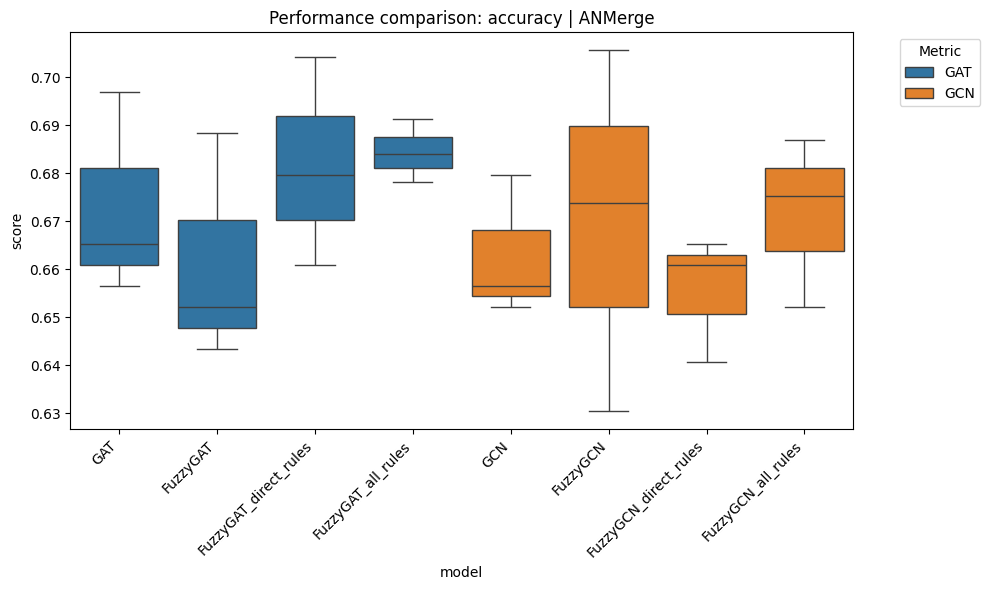

<Figure size 1200x600 with 0 Axes>

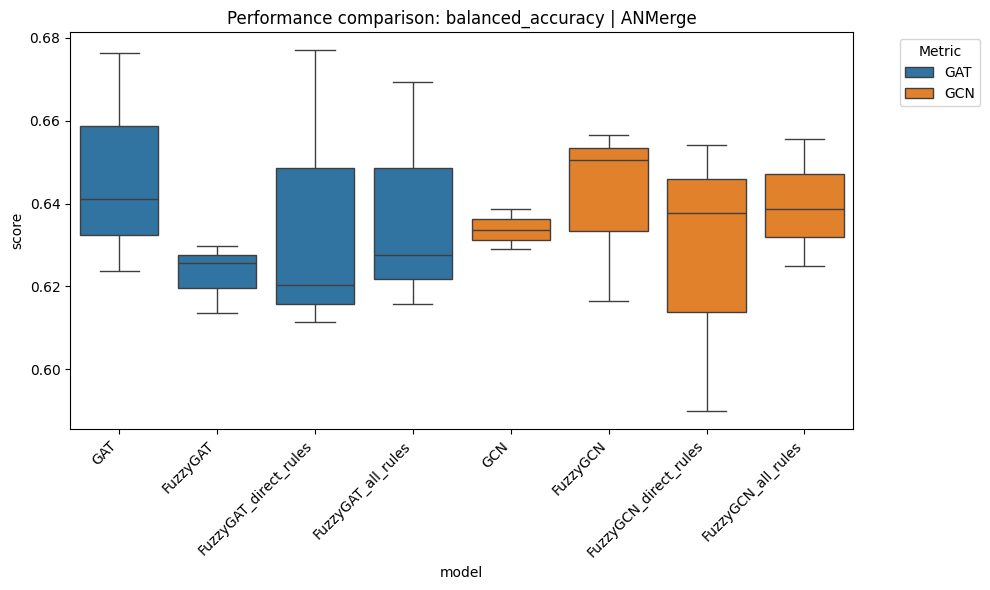

<Figure size 1200x600 with 0 Axes>

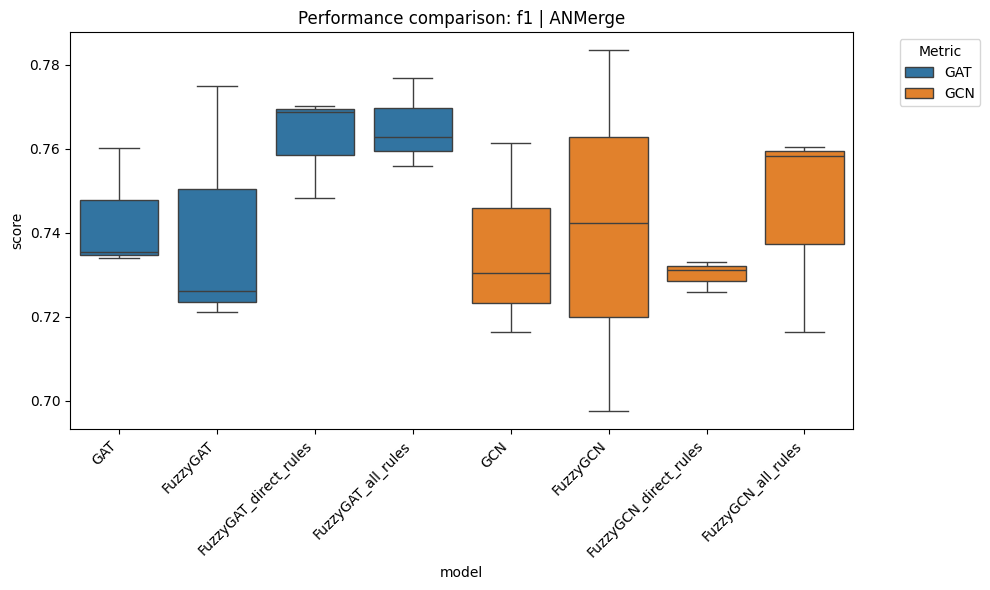

<Figure size 1200x600 with 0 Axes>

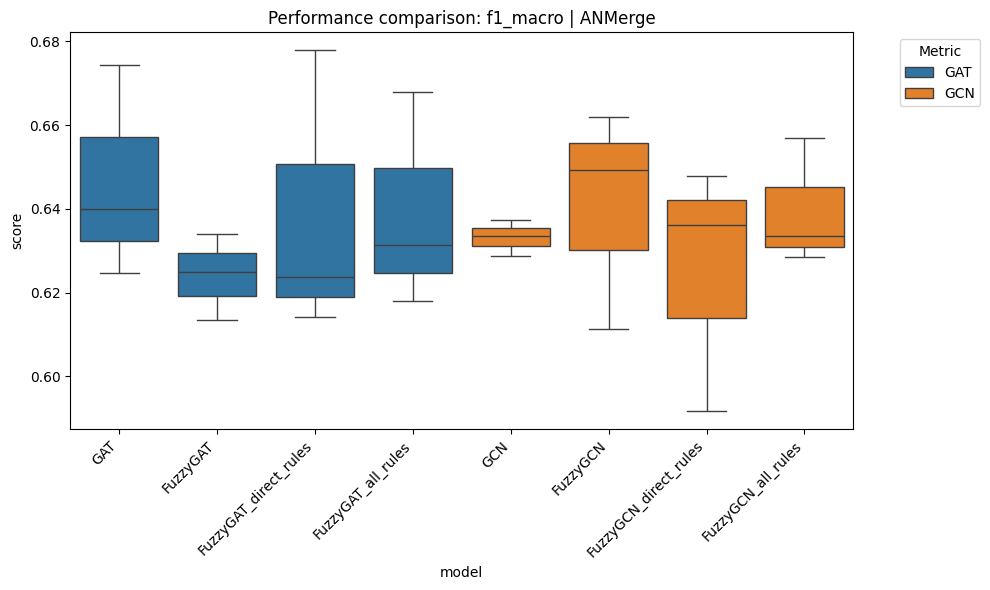

<Figure size 1200x600 with 0 Axes>

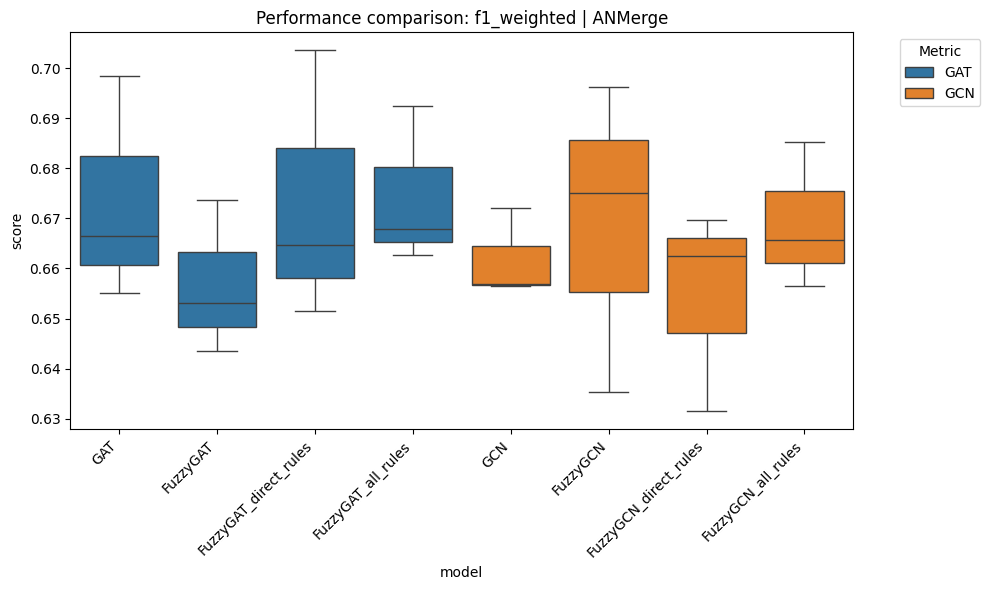

<Figure size 1200x600 with 0 Axes>

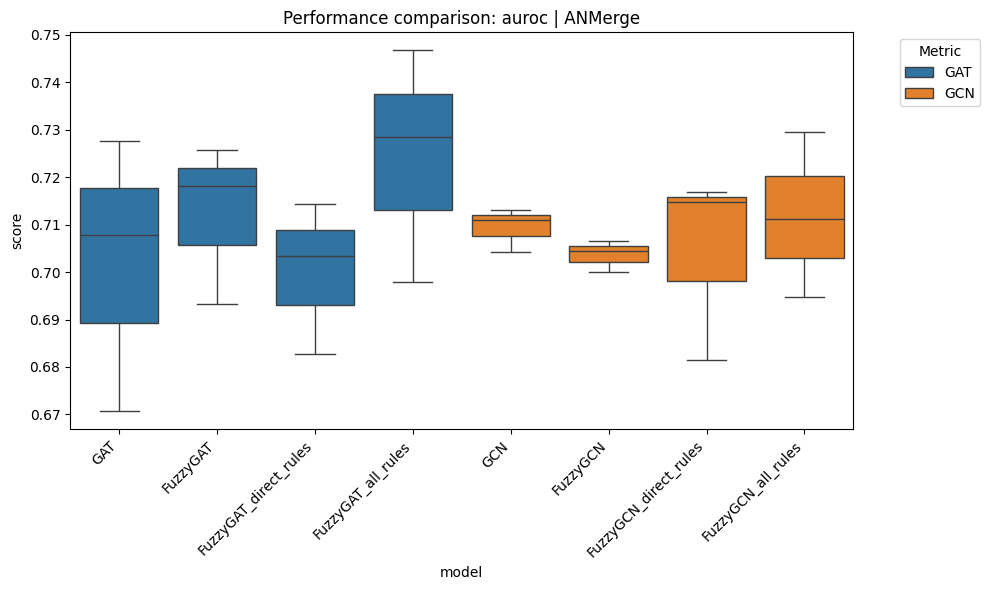

<Figure size 1200x600 with 0 Axes>

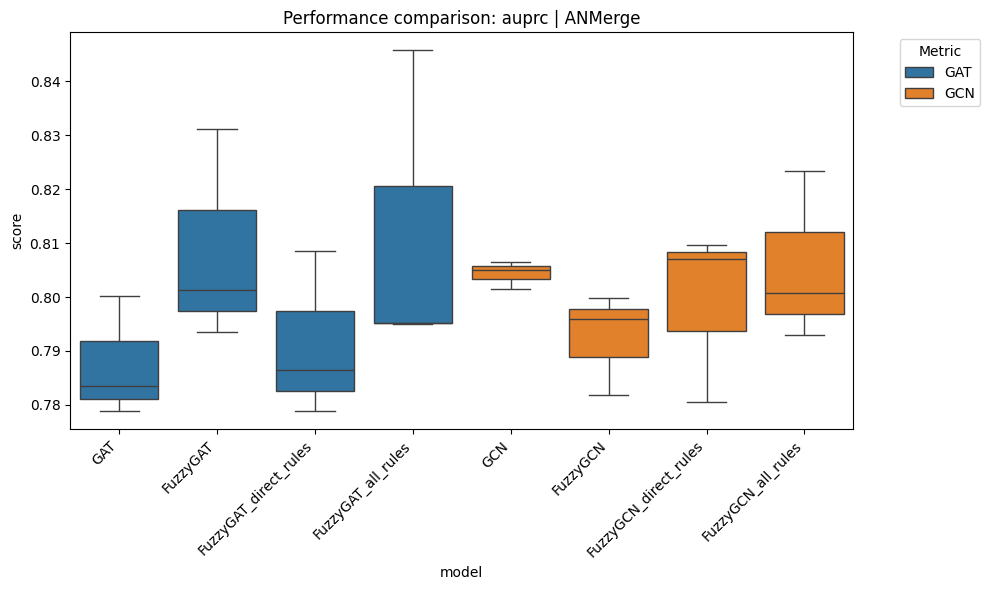

In [10]:
root_dir = "../nesy_gnn/results/updated/AD_KG"
df_metrics = parse_cv_metrics(root_dir)
df = df_metrics.melt(
    id_vars=[
        "dataset",
        "k",
        "model",
        "fold"
    ],
    value_vars=['accuracy', 'balanced_accuracy', 'f1', 'f1_macro',
       'f1_weighted', 'auroc', 'auprc'],
    var_name="metric",
    value_name="score",
)
dataset = 'ANMerge'
for metric in ['accuracy', 'balanced_accuracy', 'f1', 'f1_macro',
       'f1_weighted', 'auroc', 'auprc']:
    boxplot_comparison(df, metric, dataset)


## Check Fuzzy Rules params

In [23]:
param_path = "../nesy_gnn/results/updated/AD_KG/ANMerge/4/GAT/cv_fuzzy_params.pkl"
with open(param_path,'rb') as f:
    params = pickle.load(f)
topo_rule_params = params['FuzzyGAT']
direct_rule_params = params['FuzzyGAT_direct_rules']
all_rule_params = params['FuzzyGAT_all_rules']


In [40]:
rules_path = "../nesy_gnn/results/updated/AD_KG/ANMerge/4/GAT/cv_fuzzy_rules.pkl"
with open(rules_path, 'rb') as f:
    rules = pickle.load(f)

topo_rule_scores = rules['FuzzyGAT']
direct_rule_scores = rules['FuzzyGAT_direct_rules']
all_rule_scores = rules['FuzzyGAT_all_rules']

In [28]:
import json

meta_path = "../nesy_gnn/results/updated/AD_KG/ANMerge/4/graph_meta.json"
with open(meta_path, 'rb') as f:
    meta = json.load(f)

all_rules = meta['rule_names']
direct_rules = meta['direct_rule_names']
topo_features = ['degrees', 'clustering', 'eigenvector_centrality', 'degree_centrality', 'avg_edge_weight']

In [43]:
def rule_params_to_df(rule_params:list[dict],rule_name_col:list): 
    data = {}

    # Set the index column (topo_features)
    data['rule_name'] = rule_name_col

    # Dynamically add columns for each fold's alpha and theta
    for fold_idx, param_dict in enumerate(rule_params):
        fold_num = fold_idx + 1
        
        # Extract tensors and convert them to standard Python lists/floats
        # .detach().tolist() is used here assuming these are PyTorch parameters with gradients
        alpha_vals = param_dict['alpha'].detach().tolist()
        theta_vals = param_dict['theta'].detach().tolist()
        
        data[f'alpha_fold_{fold_num}'] = alpha_vals
        data[f'theta_fold_{fold_num}'] = theta_vals

    # 2. Create the DataFrame
    df = pd.DataFrame(data)

    # Optional: Set 'rule_name' as the index of the DataFrame
    df.set_index('rule_name', inplace=True)
    return df

In [38]:
df_topo_rules = rule_params_to_df(topo_rule_params, topo_features)
df_direct_rules = rule_params_to_df(direct_rule_params, topo_features+direct_rules)
df_all_rules = rule_params_to_df(all_rule_params, topo_features+all_rules)
df_all_rules

,alpha_fold_1,theta_fold_1,alpha_fold_2,theta_fold_2,alpha_fold_3,theta_fold_3
rule_name,,,,,,
degrees,0.988220,0.000575,1.054107,0.011454,1.013064,0.009992
clustering,0.988756,0.007243,0.971852,0.011988,1.155328,-0.025966
eigenvector_centrality,0.994893,0.002617,1.040928,0.016042,1.037127,0.008381
degree_centrality,1.020498,-0.002413,1.017354,0.002586,1.083279,-0.003467
avg_edge_weight,1.000714,-0.001886,1.024274,-0.007626,0.991313,0.003207
...,...,...,...,...,...,...
chain_AKAP13_4hops_AD,1.002423,-0.001847,0.999864,-0.000189,1.008671,0.008550
chain_VPS35_5hops_AD,0.999959,-0.000581,1.000669,0.001652,1.011510,0.010883
chain_VPS35_5hops_CTL,0.999678,-0.000887,1.005141,-0.001068,1.004227,-0.004025


### rule scores

In [45]:
print('direct rule scores:',direct_rule_scores[0].size(),'\n')
rules

direct rule scores: torch.Size([691, 190]) 



{'FuzzyGAT': [tensor([[0.4942, 0.4544, 0.4406, 0.4940, 0.5391],
          [0.4942, 0.4544, 0.5524, 0.4940, 0.5272],
          [0.4942, 0.6207, 0.5179, 0.4940, 0.5007],
          ...,
          [0.4109, 0.6207, 0.4313, 0.4085, 0.5196],
          [0.9354, 0.3515, 0.6465, 0.9397, 0.5375],
          [0.3324, 0.2977, 0.4188, 0.3282, 0.5386]]),
  tensor([[0.4957, 0.4401, 0.4302, 0.4945, 0.5401],
          [0.4957, 0.4401, 0.5507, 0.4945, 0.5279],
          [0.4957, 0.6173, 0.5134, 0.4945, 0.5009],
          ...,
          [0.4098, 0.6173, 0.4203, 0.4084, 0.5202],
          [0.9406, 0.3322, 0.6519, 0.9407, 0.5385],
          [0.3292, 0.2769, 0.4069, 0.3277, 0.5396]]),
  tensor([[0.4931, 0.4547, 0.4358, 0.4943, 0.5394],
          [0.4931, 0.4547, 0.5518, 0.4943, 0.5274],
          [0.4931, 0.6294, 0.5160, 0.4943, 0.5007],
          ...,
          [0.4041, 0.6294, 0.4263, 0.4095, 0.5198],
          [0.9459, 0.3466, 0.6493, 0.9383, 0.5379],
          [0.3209, 0.2905, 0.4133, 0.3298, 0.5389]])],
